<a href="https://colab.research.google.com/github/shubham0109/langgraph-learning/blob/main/AIAgent1_Simple_AI_Bot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install langchain-openai langchain-core langgraph python-dotenv


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 20.6 MB/s eta 0:00:00
  Attempting uninstall: langsmith
    Found existing installation: langsmith 0.14.2
    Uninstalling langsmith-0.14.2:
      Successfully uninstalled langsmith-0.14.2
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.6.6
    Uninstalling langchain-core-1.6.6:
      Successfully uninstalled langchain-core-1.6.6


In [10]:
!pip install langchain-google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 19.9 MB/s eta 0:00:00
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [8]:
from typing import TypedDict, List
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv # used to store secret stuff like API keys or configuration values

In [11]:
from langchain_google_genai import ChatGoogleGenerativeAI

In [12]:
load_dotenv()

class AgentState(TypedDict):
    messages: List[HumanMessage]

In [5]:
# import os
# from getpass import getpass

# # Try to get the key from environment variables or Colab Secrets securely
# openai_api_key = os.environ.get("OPENAI_API_KEY")

# if not openai_api_key:
#     try:
#         from google.colab import userdata
#         openai_api_key = userdata.get('OPENAI_API_KEY')
#     except Exception:
#         # Fallback if Colab Secrets is not configured or times out
#         openai_api_key = getpass("Enter your OpenAI API Key: ")

# os.environ["OPENAI_API_KEY"] = openai_api_key

# llm = ChatOpenAI(model="gpt-4o")

In [16]:
import os
from getpass import getpass

# Securely load the Google Gemini API key
gemini_api_key = os.environ.get("GEMINI_API_KEY")

if not gemini_api_key:
    try:
        from google.colab import userdata
        gemini_api_key = userdata.get('GEMINI_API_KEY')
    except Exception:
        gemini_api_key = getpass("Enter your Gemini API Key (from Google AI Studio): ")

os.environ["GEMINI_API_KEY"] = gemini_api_key

# Initialize the free Gemini 2.5 Flash model
llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", google_api_key=gemini_api_key)

In [18]:
def process(state: AgentState) -> AgentState:
    response = llm.invoke(state["messages"])
    print(f"\nAI: {response.content}")
    return state

In [20]:
graph = StateGraph(AgentState)
graph.add_node("process", process)
graph.add_edge(START, "process")
graph.add_edge("process", END)
agent = graph.compile()

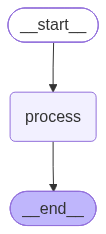

In [22]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [ ]:
user_input = input("Enter: ")
while user_input != "exit":
    agent.invoke({"messages": [HumanMessage(content=user_input)]})
    user_input = input("Enter: ")